# Zilionis 2019 NSCLC — 02 · Manifold & trajectory

Fit a scFates principal graph to the malignant manifold. **The geometry (branching vs non-branching) is decided by biology**, not by an ElPiGraph node count. We score the three developmental modules, ask whether Gast and pSom form a **co-expression hub** that diverges into two competing arms, test PPT-tree branch-point stability on the transcriptome, and — finding no stable hub or branch point — fit a fold-free **curve** (non-branching), root it at the developmental origin, and verify continuity off an independent embedding.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, io, contextlib
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
ds   = name.split('-')[0] if '-' in name else name
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


### Load processed manifold; score developmental modules
`score_genes` for Gast/pSom/Crest against the union control pool, then graph-smooth the scores (kNN-connectivity averaging) so geography is read from a de-noised field rather than per-cell noise (inDrop is sparse). The deliverable panels in 03 show the **raw** scores.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; from numpy.linalg import svd
c = xy - xy.mean(0); u, s_, vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s_[0]/s_[1]:.2f} (roundish, not an elongated strip)')

feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | raw mean {adata.obs[lab].mean():+.4f}')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

malignant manifold: 3920 cells
UMAP aspect ratio (major/minor std): 1.10 (roundish, not an elongated strip)
Gast: 79/81 genes present | raw mean -0.0092
pSom: 95/98 genes present | raw mean +0.0386
Crest: 104/104 genes present | raw mean -0.0225


### Geometry from biology (1): is there a Gast/pSom co-expression HUB?
The Puram **branching** pattern requires a hub where Gast+pSom **co-express** before diverging into two arms. We test co-occurrence enrichment of Gast-high & pSom-high cells (>1 = co-expressed hub; <1 = mutually exclusive, no hub). We also report both the `score_genes` correlations (the gate currency, Puram anchor −0.49) and the raw mean-expression correlations, which reveal that the apparent anti-correlation is largely the control-pool subtraction — the underlying developmental genes are co-activated.

In [4]:
def enrich(a, b, q=0.75):
    ah = a >= np.quantile(a, q); bh = b >= np.quantile(b, q)
    return (ah & bh).mean() / (ah.mean()*bh.mean())
e_sm = enrich(adata.obs['Gast_sm'].values, adata.obs['pSom_sm'].values)
e_raw = enrich(adata.obs['Gast'].values, adata.obs['pSom'].values)
print(f'Gast-high & pSom-high co-occurrence enrichment: smoothed {e_sm:.2f}, raw {e_raw:.2f} '
      '(<1 => mutually exclusive => NO co-expression hub)')
print('\nscore_genes (gate currency) spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
print('raw mean-expression (no control pool) correlations — developmental genes co-activate:')
import numpy as _np
def _mz(gl):
    X=adata[:,[x for x in gl if x in adata.var_names]].X; X=X.toarray() if sp.issparse(X) else _np.asarray(X)
    m=X.mean(1); return (m-m.mean())/m.std()
rz={k:_mz(feat[v].tolist()) for k,v in [('Gast','GSE162534'),('pSom','GSE229103'),('Crest','rRNAModifications')]}
for a,b in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]:
    print(f'  {a} vs {b}: r = {_np.corrcoef(rz[a],rz[b])[0,1]:+.3f}')

Gast-high & pSom-high co-occurrence enrichment: smoothed 0.07, raw 0.70 (<1 => mutually exclusive => NO co-expression hub)

score_genes (gate currency) spatial correlations:
  Gast_sm vs pSom_sm: r = -0.531
  Crest_sm vs Gast_sm: r = -0.514
  Crest_sm vs pSom_sm: r = -0.359
raw mean-expression (no control pool) correlations — developmental genes co-activate:
  Gast vs pSom: r = +0.583
  Gast vs Crest: r = +0.446
  pSom vs Crest: r = +0.505


### Geometry from biology (2): is there a STABLE branch point?
A tree is only warranted if a branch point is stable. We fit the PPT tree on the **transcriptome** (Harmony-PCA, the representation the manifold is built from) across node counts and seeds, and contrast with the UMAP. A stable 2-tips/0-forks on the transcriptome vs seed-unstable forks on the UMAP is the signature of a **continuous cloud**, not a genuine bifurcation — fitting a tree here would spider spuriously over the cloud (the spec's forbidden tree-on-a-strip).

In [5]:
def diag(ad):
    B=np.asarray(ad.uns['graph']['B']); deg=(B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
adata.obsm['X_hpca'] = adata.obsm['X_pca_harmony'][:,:20]
print('PPT tree tips/forks — transcriptome (X_pca_harmony) vs UMAP, across node x seed:')
for rep in ['X_hpca','X_umap']:
    for N in [40, 50, 60]:
        row=[]
        for sd in [0,1,2]:
            with contextlib.redirect_stdout(io.StringIO()):
                scf.tl.tree(adata, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=0.5,
                            use_rep=rep, seed=sd, plot=False)
            t,f=diag(adata); row.append(f'{t}t/{f}f')
        print(f'  {rep:14s} Nodes={N}: ' + '  '.join(row))
print('\n-> transcriptome: stable 2t/0f (no branch point); UMAP forks are seed-unstable spidering.')
print('-> no co-expression hub + no stable branch point => NON-BRANCHING. Fit a curve, not a tree.')

PPT tree tips/forks — transcriptome (X_pca_harmony) vs UMAP, across node x seed:
  X_hpca         Nodes=40: 2t/0f  2t/0f  2t/0f
  X_hpca         Nodes=50: 2t/0f  2t/0f  2t/0f
  X_hpca         Nodes=60: 2t/0f  2t/0f  2t/0f
  X_umap         Nodes=40: 3t/1f  4t/2f  4t/2f
  X_umap         Nodes=50: 4t/2f  3t/1f  4t/2f
  X_umap         Nodes=60: 4t/2f  4t/2f  4t/2f

-> transcriptome: stable 2t/0f (no branch point); UMAP forks are seed-unstable spidering.
-> no co-expression hub + no stable branch point => NON-BRANCHING. Fit a curve, not a tree.


### Proliferation is orthogonal to the developmental axis
Cycling is a scattered 6.4% minority; the module gene sets carry ~no cell-cycle genes and the Gast↔pSom relationship is unchanged in non-cycling cells — so proliferation is not confounding the axis and no compartment is scoped out.

In [6]:
nc = ~adata.obs['cycling'].values
rw = np.corrcoef(adata.obs['Gast_sm'], adata.obs['pSom_sm'])[0,1]
rn = np.corrcoef(adata.obs['Gast_sm'][nc], adata.obs['pSom_sm'][nc])[0,1]
print(f'Gast_sm~pSom_sm: whole {rw:+.3f}; non-cycling (n={nc.sum()}) {rn:+.3f} (unchanged)')
print('overall cycling fraction: %.3f -> keep whole manifold (no scoping)' % adata.obs['cycling'].mean())

Gast_sm~pSom_sm: whole -0.531; non-cycling (n=3671) -0.527 (unchanged)
overall cycling fraction: 0.064 -> keep whole manifold (no scoping)


### Fit the curve and verify it is fold-free
A curve is valid only if it does not fold back through the cloud. `fold_diag` reports tips, forks, and the minimum self-approach of graph-distant nodes relative to the median edge length (>1 = fold-free). We assert zero forks and no fold before trusting the pseudotime.

In [7]:
def fold_diag(ad):
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin=np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin=min(dmin,np.sqrt(((F[a]-F[b])**2).sum()))
    tips=int(((B>0).sum(0)==1).sum()); forks=int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
print('curve stability across node counts:')
for N in [15,20,30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(adata, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,t,f = fold_diag(adata)
    print(f'  Nodes={N}: {t} tips {f} forks, fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,t,f = fold_diag(adata); assert f==0 and sa>1, 'topology check failed'
print(f'committed Nodes=20: {t} tips, {f} forks, self-approach {sa:.2f}')

curve stability across node counts:
  Nodes=15: 2 tips 0 forks, fold self-approach ratio = 2.86 (>1 = fold-free)
  Nodes=20: 2 tips 0 forks, fold self-approach ratio = 2.45 (>1 = fold-free)
  Nodes=30: 2 tips 0 forks, fold self-approach ratio = 2.19 (>1 = fold-free)
committed Nodes=20: 2 tips, 0 forks, self-approach 2.45


### Root from developmental order, compute pseudotime
Score each tip by its smoothed module means and root at the **Gast-high** tip — gastrulation is the earliest developmental programme (the origin). pSom is the later programme; Crest is a *late/lateral* readout and is never the root.

In [8]:
B=np.asarray(adata.uns['graph']['B']); F=np.asarray(adata.uns['graph']['F']).T
tips=np.where((B>0).sum(0)==1)[0]
R=np.asarray(adata.obsm['X_R']); hard=R.argmax(1)
D=shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info={}
for tp in tips:
    m=np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp]=(adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root=int(max(tips, key=lambda tp: info[tp][0]))
print('derived root = tip', root, '(Gast-high developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t=adata.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for sn in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t, adata.obs[sn]); print(f'  {sn}: rho = {rho:+.3f}')

tip 0: Gast=-0.0213 pSom=+0.0440 Crest=-0.0193
tip 2: Gast=-0.0005 pSom=+0.0309 Crest=-0.0211
derived root = tip 2 (Gast-high developmental origin)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.587
  pSom_sm: rho = +0.762
  Crest_sm: rho = +0.019


### Continuity off an independent embedding
The curve was fit on the UMAP, so continuity cannot be judged with a UMAP-neighbour metric (blind to a fold in that same UMAP — the Kürten failure mode). We check pseudotime against a **diffusion-map** component the curve never touched.

In [9]:
sc.tl.diffmap(adata, n_comps=15)
dc1 = adata.obsm['X_diffmap'][:,1]
rho_dc,_ = spearmanr(t, dc1)
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an independent embedding')
print('monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

continuity: corr(pseudotime, diffusion DC1) = -0.85 on an independent embedding
monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.


### Orient to the house linear layout (pseudotime left → right)
A rigid rotation aligning the pseudotime axis to the x-axis (distances preserved — no re-embedding), so every trajectory panel reads left(root)→right(terminus).

In [10]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
# rigid rotation: principal axis of the (x,y) cloud -> x; then sign so low pt is on the left
c = xy - xy.mean(0); u,ss,vt = np.linalg.svd(c, full_matrices=False)
xyr = c @ vt.T
if np.corrcoef(xyr[:,0], t)[0,1] < 0: xyr[:,0] = -xyr[:,0]
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
# distance preservation sanity check
d0 = np.linalg.norm(xy[:50]-xy[:50].mean(0), axis=1); d1 = np.linalg.norm(xyr[:50]-xyr[:50].mean(0), axis=1)
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: rigid rotation; corr(x_lin, pseudotime) = {r:+.2f}; distance corr = {np.corrcoef(d0,d1)[0,1]:.3f}')

orientation: rigid rotation; corr(x_lin, pseudotime) = +0.85; distance corr = 1.000


### Render the fitted curve on the embedding (catch folds visually)

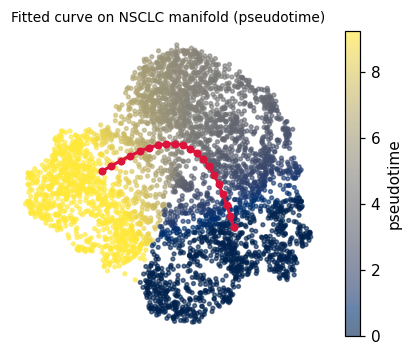

In [11]:
F = np.asarray(adata.uns['graph']['F']); Bc = np.asarray(adata.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
fig, ax = plt.subplots(figsize=(4.6, 3.6))
sca = ax.scatter(adata.obsm['X_umap'][:,0], adata.obsm['X_umap'][:,1], c=t, cmap='cividis', s=6, alpha=.6)
for a,b in zip(ii,jj):
    ax.plot([F[0,a],F[0,b]], [F[1,a],F[1,b]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=18, zorder=6)
ax.axis('off'); ax.set_title('Fitted curve on NSCLC manifold (pseudotime)', size=9)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()

### Deliverable — `manifold.pdf` + `manifold.h5ad`
The manifold panel renders the fitted curve edges over the cells so topology and fold-freeness are visually verifiable.

saved manifold.h5ad + manifold.pdf


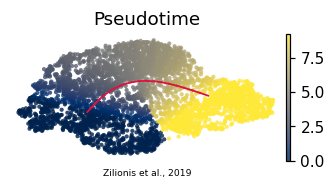

In [12]:
# sanitize non-serializable ElPiGraph uns entry before writing
if 'epg' in adata.uns: adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
# curve edges in the rotated frame
Fr = np.asarray(adata.uns['graph']['F']).T
cc = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
u,ss,vt = np.linalg.svd(cc, full_matrices=False)
Fr_rot = (Fr - adata.obsm['X_umap'].mean(0)) @ vt.T
if np.corrcoef((cc@vt.T)[:,0], t)[0,1] < 0: Fr_rot[:,0] = -Fr_rot[:,0]
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for a,b in zip(ii,jj):
    ax.plot([Fr_rot[a,0],Fr_rot[b,0]], [Fr_rot[a,1],Fr_rot[b,1]], '-', color='crimson', lw=1.2, zorder=5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')